# **주성분 분석(PCA) 완성 실습**

10,000개 픽셀 특성을 50개의 주성분으로 축소하고 원본을 재구성한다.

## 1. 데이터 다운로드와 준비

In [1]:
from pathlib import Path
import urllib.request

data_file = Path('fruits_300.npy')
if not data_file.exists():
    urllib.request.urlretrieve('https://bit.ly/fruits_300', data_file)
print('데이터 파일:', data_file.resolve())


데이터 파일: /workspace/scratch/ec3dd5e91a85/fruits_300.npy


In [2]:
import matplotlib.pyplot as plt
import numpy as np

def draw_fruits(arr, ratio=1):
    n = len(arr)
    rows = int(np.ceil(n / 10))
    cols = n if rows < 2 else 10
    fig, axs = plt.subplots(rows, cols, figsize=(cols * ratio, rows * ratio), squeeze=False)
    for i in range(rows):
        for j in range(cols):
            axs[i, j].axis('off')
            idx = i * 10 + j
            if idx < n:
                axs[i, j].imshow(arr[idx], cmap='gray_r')
    plt.tight_layout()
    plt.show()

fruits = np.load('fruits_300.npy')
fruits_2d = fruits.reshape(-1, 100 * 100)
print('원본:', fruits.shape, '펼친 데이터:', fruits_2d.shape)


원본: (300, 100, 100) 펼친 데이터: (300, 10000)


## 2. PCA 클래스

주성분 배열 크기: (50, 10000)
PCA 변환 후: (300, 50)


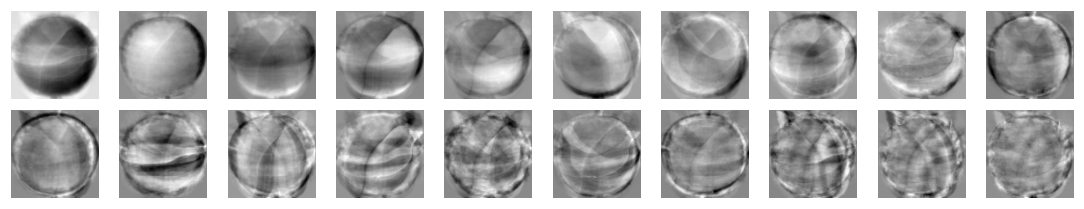

In [3]:
from sklearn.decomposition import PCA

pca = PCA(n_components=50, random_state=42)
pca.fit(fruits_2d)
print('주성분 배열 크기:', pca.components_.shape)
draw_fruits(pca.components_.reshape(-1, 100, 100)[:20])

fruits_pca = pca.transform(fruits_2d)
print('PCA 변환 후:', fruits_pca.shape)


## 3. 원본 데이터 재구성

복원 데이터: (300, 10000)


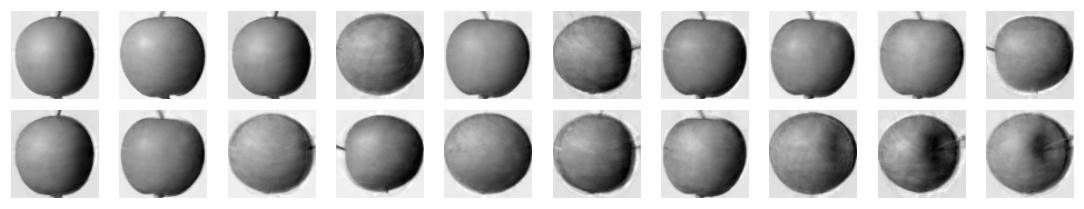

In [4]:
fruits_inverse = pca.inverse_transform(fruits_pca)
print('복원 데이터:', fruits_inverse.shape)
fruits_reconstruct = fruits_inverse.reshape(-1, 100, 100)
draw_fruits(fruits_reconstruct[:20])


## 4. 설명된 분산

50개 주성분의 누적 설명 분산: 0.9213948508475198


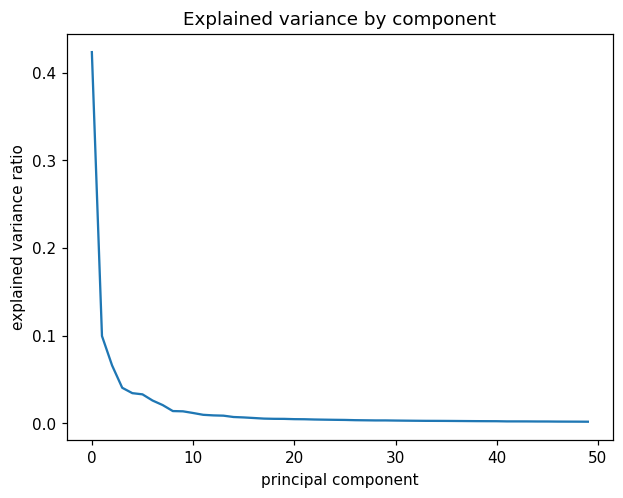

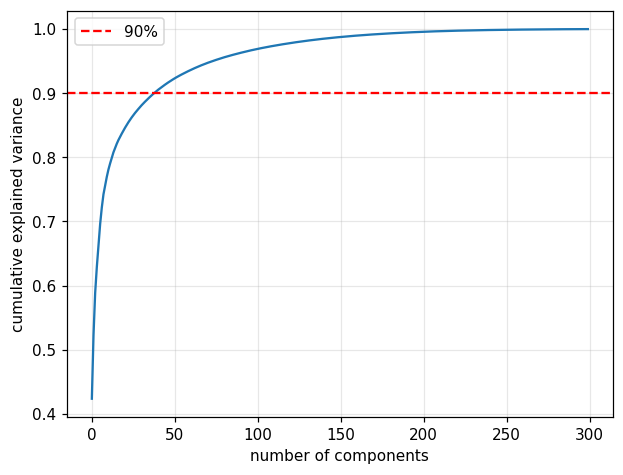

In [5]:
print('50개 주성분의 누적 설명 분산:', pca.explained_variance_ratio_.sum())
plt.plot(pca.explained_variance_ratio_)
plt.xlabel('principal component')
plt.ylabel('explained variance ratio')
plt.title('Explained variance by component')
plt.show()

pca_all = PCA()
pca_all.fit(fruits_2d)
plt.plot(np.cumsum(pca_all.explained_variance_ratio_))
plt.axhline(0.90, color='red', linestyle='--', label='90%')
plt.xlabel('number of components')
plt.ylabel('cumulative explained variance')
plt.legend()
plt.grid(alpha=0.3)
plt.show()


## 5. 다른 알고리즘과 함께 사용하기

In [6]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_validate

target = np.array([0] * 100 + [1] * 100 + [2] * 100)
lr = LogisticRegression(max_iter=1000, random_state=42)

scores_original = cross_validate(lr, fruits_2d, target, cv=5, return_train_score=True)
scores_pca = cross_validate(lr, fruits_pca, target, cv=5, return_train_score=True)

print('원본 특성 검증 정확도:', scores_original['test_score'].mean())
print('PCA 특성 검증 정확도:', scores_pca['test_score'].mean())
print('원본 평균 학습 시간:', scores_original['fit_time'].mean())
print('PCA 평균 학습 시간:', scores_pca['fit_time'].mean())
print('PCA는 특성 수를 줄여 학습 속도를 높이면서 높은 정확도를 유지합니다.')


원본 특성 검증 정확도: 0.9966666666666667
PCA 특성 검증 정확도: 0.9966666666666667
원본 평균 학습 시간: 6.529769659042358
PCA 평균 학습 시간: 0.24147233963012696
PCA는 특성 수를 줄여 학습 속도를 높이면서 높은 정확도를 유지합니다.
